# Certified capacity and Gaussian allocation

A stopping tolerance should concern the quantity of interest. The capacity solver returns a provable interval, rather than trusting a small change in parameters.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from information_lab.channels import (
    bsc,
    bec,
    z_channel,
    capacity,
    water_filling,
    bsc_normal_approximation,
)
from information_lab.information import binary_entropy

for channel, truth in [
    (bsc(0.1), 1 - binary_entropy(0.1)),
    (bec(0.25), 0.75),
    (z_channel(0.5), np.log2(5 / 4)),
]:
    result = capacity(channel)
    print(result["lower_bits"], truth, result["upper_bits"], "input", result["input"])
    assert result["lower_bits"] - 1e-9 <= truth <= result["upper_bits"] + 1e-9

0.5310044064107188 0.5310044064107189 0.5310044064107188 input [0.5 0.5]
0.7500000000000001 0.75 0.7500000000000001 input [0.5 0.5]
0.3219280948873624 0.32192809488736235 0.32192809498723735 input [0.6 0.4]


In [3]:
allocation = water_filling([0.5, 1, 2, 4], 4)
print(allocation)
assert np.isclose(allocation["power"].sum(), 4)
print("Short-block approximation:", bsc_normal_approximation(0.1, 32, 0.001))

{'power': array([2. , 1.5, 0.5, 0. ]), 'water_level': 2.5, 'capacity_bits_per_parallel_use': 1.9828921423310433}
Short-block approximation: {'capacity': 0.5310044064107189, 'dispersion_bits_squared': 0.9043582063292139, 'second_order_rate': 0.011503414399207434}


The noise/interference state can itself be useful information. Decoder-known jammer state and unknown state have different capacities; the supplied course channels also have exact checks and a degradation relation.

**Recorded configuration**

{
  "family": "channels",
  "id": "course_channel1",
  "task": "course_channel1",
  "stochastic": false
}
{
  "lower_bits": 1.1699250014423124,
  "upper_bits": 1.1699250015421876,
  "gap_bits": 9.987521920606923e-11,
  "iterations": 45,
  "converged": true
}


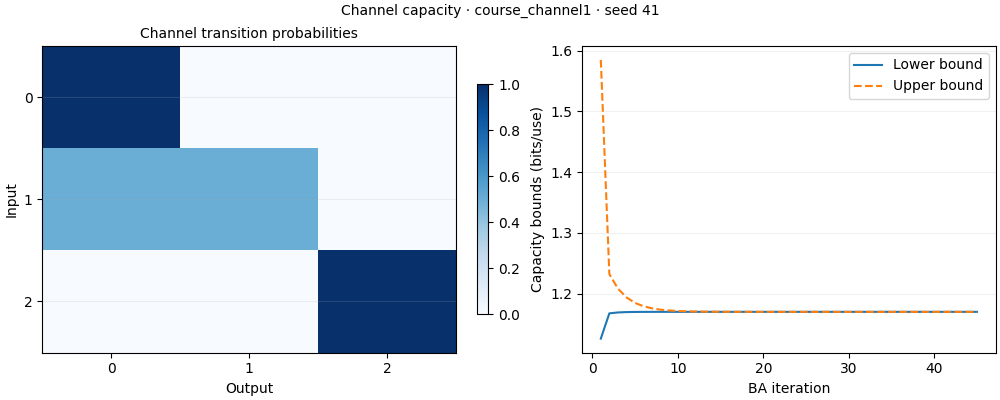

Second course channel: {'lower_bits': 0.9999999999417925, 'upper_bits': 1.0, 'gap_bits': 5.8207549891164945e-11, 'iterations': 34, 'converged': True}


In [4]:
record, path = query("channels", task="course_channel1")[0]
measured(record)
preview(record)
print("Second course channel:", query("channels", task="course_channel2")[0][0]["metrics"])

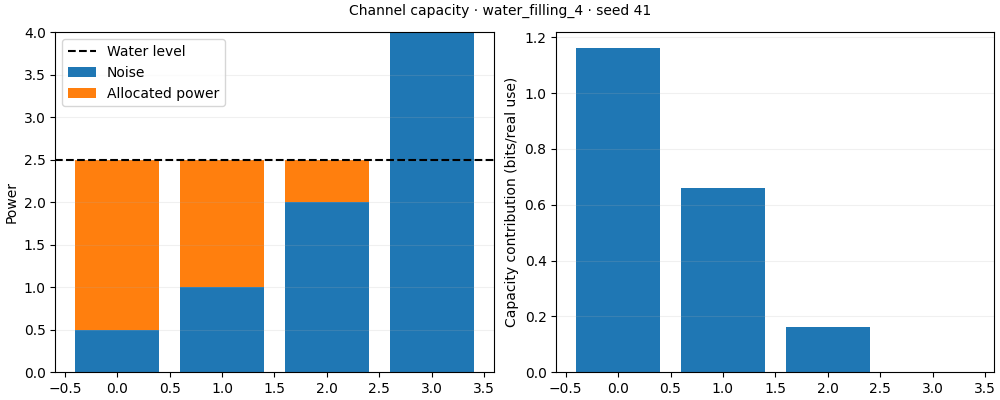

In [5]:
record, path = query("channels", task="water_filling", total_power=4)[0]
preview(record)